# 02 — Retornos y distribución empírica: preparación de entradas

Esta notebook prepara y valida las entradas locales del corte final antes de cualquier transformación o análisis estadístico. Carga la vista elegible de precios ajustados Gold y la matriz de retornos simples correspondiente. No descarga datos, no usa credenciales y no implementa todavía distribución empírica, diagnósticos, escenarios ni carteras.

## Alcance actual

El corte aprobado cubre 2018-01-02 a 2026-10-09: 2,205 fechas de precios y 2,204 retornos diarios utilizables por instrumento. La matriz Gold de precios conserva 138 series para auditoría; aquí se selecciona explícitamente, y sin persistirla, la vista de las 125 columnas que pertenecen al universo elegible.

La primera fila de retornos se conserva durante la validación porque representa la ausencia prevista de un precio anterior aprobado. Sólo después se crea una vista de retornos utilizables retirando esa fila conocida; no se usa `drop_nulls` ni se imputan datos.

In [1]:
from __future__ import annotations

import hashlib
import json
import site
import sys
from datetime import date
from pathlib import Path

def find_project_root() -> Path:
    def is_project_root(candidate: Path) -> bool:
        return ((candidate / 'config' / 'universe.csv').is_file()
                and (candidate / 'src' / 'scenario_portfolio_lab').is_dir())

    for origin in (Path.cwd(), *Path.cwd().parents):
        for candidate in (origin, origin / 'scenario-portfolio-lab', origin / 'data-science-portfolio' / 'scenario-portfolio-lab'):
            if is_project_root(candidate):
                return candidate
    raise RuntimeError(
        'Repository files config/universe.csv and src/scenario_portfolio_lab were not found. '
        'Open the notebook from the complete scenario-portfolio-lab repository (or its data-science-portfolio parent). '
        'Do not run it from an exported standalone .ipynb file.'
    )


ROOT = find_project_root()
SRC = ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

# MyST/Jupyter kernels may differ from the project virtual environment.
# Reuse already installed local dependencies when this Windows project .venv exists; never install packages here.
LOCAL_SITE_PACKAGES = ROOT / '.venv' / 'Lib' / 'site-packages'
if LOCAL_SITE_PACKAGES.is_dir():
    site.addsitedir(str(LOCAL_SITE_PACKAGES))

try:
    import exchange_calendars as xcals
    import polars as pl
except ModuleNotFoundError as exc:
    raise RuntimeError(
        'Missing project dependencies. Select the project .venv Python 3.13.2 kernel or install requirements.txt '
        'into the active kernel environment before running this notebook.'
    ) from exc

RUN_ROOT = ROOT / 'data' / 'published' / 'cut_2026-10-09_run_2026-10-11_full_window_final'
GOLD_ROOT = RUN_ROOT / 'gold'
PRICE_MATRIX_PATH = GOLD_ROOT / 'adjusted_close_matrix.parquet'
RETURN_MATRIX_PATH = GOLD_ROOT / 'eligible_simple_total_return_matrix.parquet'
RUN_MANIFEST_PATH = RUN_ROOT / 'run_manifest.json'
ELIGIBLE_CATALOG_PATH = RUN_ROOT / 'reports' / 'eligible_universe.csv'

for required in (PRICE_MATRIX_PATH, RETURN_MATRIX_PATH, RUN_MANIFEST_PATH, ELIGIBLE_CATALOG_PATH):
    if not required.is_file():
        raise FileNotFoundError(f'Required final-cut artifact is missing: {required.relative_to(ROOT)}')


## Carga del manifiesto y catálogo elegible

El manifiesto final contiene hashes de los 138 raw que alimentaron el corte. Esta notebook los comprueba contra sus referencias previas. El manifiesto no contiene hashes de referencia para los dos Parquet matriciales; por ello valida su estructura y contenido, pero no los presenta como verificados criptográficamente contra una referencia previa.

In [2]:
run_manifest = json.loads(RUN_MANIFEST_PATH.read_text(encoding='utf-8'))
approved_period = run_manifest['approved_period']
assert approved_period == {'start': '2018-01-02', 'end': '2026-10-09'}

eligible_catalog = pl.read_csv(ELIGIBLE_CATALOG_PATH).filter(pl.col('universe_status') == 'ELIGIBLE')
eligible_symbols = eligible_catalog['symbol'].to_list()
assert len(eligible_symbols) == 125 and len(set(eligible_symbols)) == 125

raw_hash_checks = []
for symbol, reference in run_manifest['raw'].items():
    raw_path = ROOT / Path(reference['path'].replace('\\', '/'))
    if not raw_path.is_file():
        raise FileNotFoundError(f'Manifest-referenced raw is missing for {symbol}.')
    raw_hash_checks.append(hashlib.sha256(raw_path.read_bytes()).hexdigest() == reference['sha256'])
assert len(raw_hash_checks) == 138 and all(raw_hash_checks)


## Carga y validación de matrices

Las sesiones esperadas se reconstruyen desde el calendario común documentado en el manifiesto (`exchange_calendars:US_EQUITY_COMMON(XNYS=XNAS=ARCX)`). Las validaciones son explícitas: fechas, orden de símbolos, precios, nulos previstos en retornos y finitud.

In [3]:
all_gold_prices = pl.read_parquet(PRICE_MATRIX_PATH)
return_matrix = pl.read_parquet(RETURN_MATRIX_PATH)

assert all_gold_prices.columns[0] == return_matrix.columns[0] == 'session_date'
return_symbols = return_matrix.columns[1:]
assert return_symbols == eligible_symbols
assert set(return_symbols).issubset(set(all_gold_prices.columns[1:]))

# Explicit ordered view: not a new persisted matrix and not a silent filter.
eligible_prices = all_gold_prices.select(['session_date', *return_symbols])
assert eligible_prices.width == return_matrix.width == 126
assert eligible_prices.height == return_matrix.height == 2205

start, end = date.fromisoformat(approved_period['start']), date.fromisoformat(approved_period['end'])
expected_dates = [stamp.date() for stamp in xcals.get_calendar('XNYS').sessions if start <= stamp.date() <= end]
for matrix in (eligible_prices, return_matrix):
    dates = matrix['session_date'].to_list()
    assert dates == expected_dates
    assert dates == sorted(dates) and len(set(dates)) == len(dates) == 2205

price_values = eligible_prices.select(pl.exclude('session_date'))
assert all(value == 0 for value in price_values.null_count().row(0))
assert not any(price_values.select(pl.all().is_nan().any()).row(0))
assert not any(price_values.select(pl.all().is_infinite().any()).row(0))
assert not any(price_values.select((pl.all() <= 0).any()).row(0))

first_return_row = return_matrix.slice(0, 1).select(pl.exclude('session_date'))
subsequent_return_rows = return_matrix.slice(1).select(pl.exclude('session_date'))
assert all(value == 1 for value in return_matrix.select(pl.exclude('session_date').null_count()).row(0))
assert all(value == 1 for value in first_return_row.null_count().row(0))
assert all(value == 0 for value in subsequent_return_rows.null_count().row(0))
assert not any(subsequent_return_rows.select(pl.all().is_nan().any()).row(0))
assert not any(subsequent_return_rows.select(pl.all().is_infinite().any()).row(0))


## Vista explícita de retornos utilizables

La siguiente vista retira solamente la primera fila prevista, ya comprobada como nula para los 125 instrumentos. Conserva las fechas y el orden explícito de símbolos de la matriz elegible. No se calculan transformaciones ni estadísticas.

In [4]:
usable_returns = return_matrix.slice(1).select(['session_date', *return_symbols])
assert usable_returns.shape == (2204, 126)
assert usable_returns['session_date'].to_list() == expected_dates[1:]
assert usable_returns.columns[1:] == return_symbols
assert all(value == 0 for value in usable_returns.select(pl.exclude('session_date').null_count()).row(0))

validation_summary = pl.DataFrame({
    'check': [
        'Approved period',
        'Expected and observed price dates',
        'Eligible symbols',
        'Eligible adjusted-price view',
        'Eligible simple-return matrix',
        'Usable-return view',
        'Manifest-referenced raw hashes',
        'Matrix reference hashes',
    ],
    'result': [
        '2018-01-02 to 2026-10-09',
        '2,205 ordered, unique XNYS common sessions',
        '125 exact symbols, explicit order',
        '2,205 rows × (date + 125); positive, finite, no nulls',
        '2,205 rows × (date + 125); first-row null only, finite thereafter',
        '2,204 rows × (date + 125); dates retained, no nulls',
        '138/138 verified against manifest references',
        'Not available in run_manifest; no new hash is treated as prior evidence',
    ],
})
validation_summary


check,result
str,str
"""Approved period""","""2018-01-02 to 2026-10-09"""
"""Expected and observed price da…","""2,205 ordered, unique XNYS com…"
"""Eligible symbols""","""125 exact symbols, explicit or…"
"""Eligible adjusted-price view""","""2,205 rows × (date + 125); pos…"
"""Eligible simple-return matrix""","""2,205 rows × (date + 125); fir…"
"""Usable-return view""","""2,204 rows × (date + 125); dat…"
"""Manifest-referenced raw hashes""","""138/138 verified against manif…"
"""Matrix reference hashes""","""Not available in run_manifest;…"


# 1. Retornos simples y log-retornos

Con los precios ajustados, el retorno simple es $r_t=P_t^{adj}/P_{t-1}^{adj}-1$. El log-retorno es $\ell_t=\log(1+r_t)$ y permite recuperar el retorno simple con $r_t=\exp(\ell_t)-1$.

Los cálculos usan decimales: `0.01` se presenta como `1%`. La transformación cambia la representación, no el rendimiento económico; no filtra, recorta ni imputa observaciones.

In [5]:
import numpy as np

simple_return_values = usable_returns.select(pl.exclude('session_date')).to_numpy()
domain_failures = np.argwhere(simple_return_values <= -1.0)
if domain_failures.size:
    examples = [{'session_date': str(usable_returns['session_date'][int(i)]), 'symbol': return_symbols[int(j)], 'simple_return': float(simple_return_values[i, j])} for i, j in domain_failures[:10]]
    raise ValueError(f'Log-return domain failure (r <= -1); first locations: {examples}')
log_return_values = np.log1p(simple_return_values)
if not np.isfinite(log_return_values).all():
    raise ValueError('Log-return transformation produced a non-finite value.')
log_returns = pl.DataFrame({'session_date': usable_returns['session_date'], **{symbol: log_return_values[:, i] for i, symbol in enumerate(return_symbols)}})
assert log_returns.columns == usable_returns.columns and log_returns.shape == (2204, 126)
assert all(value == 0 for value in log_returns.select(pl.exclude('session_date').null_count()).row(0))

# Rule: first usable date and first three symbols in the explicit matrix order; no performance-based selection.
illustration_rows = []
for symbol in return_symbols[:3]:
    log_return = float(log_returns[symbol][0])
    illustration_rows.append({'session_date': usable_returns['session_date'][0], 'symbol': symbol, 'adjusted_price_previous': float(eligible_prices[symbol][0]), 'adjusted_price_current': float(eligible_prices[symbol][1]), 'simple_return_decimal': float(usable_returns[symbol][0]), 'log_return': log_return, 'recovered_simple_return': float(np.expm1(log_return))})
illustration_table = pl.DataFrame(illustration_rows)
illustration_table


session_date,symbol,adjusted_price_previous,adjusted_price_current,simple_return_decimal,log_return,recovered_simple_return
date,str,f64,f64,f64,f64,f64
2018-01-03,"""AA""",52.459843,51.822756,-0.012144,-0.012219,-0.012144
2018-01-03,"""AAL""",51.648665,51.015119,-0.012266,-0.012342,-0.012266
2018-01-03,"""AAPL""",40.233642,40.226635,-0.000174,-0.000174,-0.000174


## Comprobaciones sobre los 125 instrumentos

Las identidades se aplican a las 2,204 observaciones de los 125 instrumentos completos. Las tolerancias de doble precisión son absoluta `1e-12` y relativa `1e-10`; el error relativo se reporta sólo si la referencia no es cero y, si lo es, controla la tolerancia absoluta. No se redondea antes de validar.

In [6]:
ABSOLUTE_TOLERANCE, RELATIVE_TOLERANCE = 1e-12, 1e-10
def identity_metrics(actual, reference):
    absolute_error = np.abs(actual - reference)
    nonzero = np.abs(reference) > 0.0
    relative_error = np.full(reference.shape, np.nan); relative_error[nonzero] = absolute_error[nonzero] / np.abs(reference[nonzero])
    return {'max_absolute_error': float(absolute_error.max()), 'max_relative_error_nonzero_reference': float(np.nanmax(relative_error)) if nonzero.any() else None, 'zero_reference_count': int((~nonzero).sum()), 'passed': bool(np.all(absolute_error <= ABSOLUTE_TOLERANCE + RELATIVE_TOLERANCE * np.abs(reference)))}

round_trip = identity_metrics(np.expm1(log_return_values), simple_return_values)
previous_prices = eligible_prices.slice(0, 2204).select(pl.exclude('session_date')).to_numpy()
current_prices = eligible_prices.slice(1, 2204).select(pl.exclude('session_date')).to_numpy()
assert usable_returns['session_date'].to_list() == eligible_prices['session_date'].slice(1, 2204).to_list()
assert usable_returns.columns[1:] == eligible_prices.columns[1:] == log_returns.columns[1:]
price_correspondence = identity_metrics(log_return_values, np.log(current_prices) - np.log(previous_prices))
simple_compounded = np.prod(1.0 + simple_return_values, axis=0) - 1.0
log_compounded = np.expm1(np.sum(log_return_values, axis=0))
endpoint_compounded = current_prices[-1] / previous_prices[0] - 1.0
checks = [('Round trip: expm1(log1p(r)) vs r', round_trip), ('Price correspondence: log1p(r) vs log(P_t)-log(P_t-1)', price_correspondence), ('Time composition: simple product vs log sum', identity_metrics(simple_compounded, log_compounded)), ('Time composition: simple product vs price endpoints', identity_metrics(simple_compounded, endpoint_compounded)), ('Time composition: log sum vs price endpoints', identity_metrics(log_compounded, endpoint_compounded))]
failures = [(name, metric) for name, metric in checks if not metric['passed']]
if failures: raise AssertionError(f'Identity validation failed without altering data: {failures}')
identity_summary = pl.DataFrame({'check': [name for name, _ in checks], 'max_absolute_error': [metric['max_absolute_error'] for _, metric in checks], 'max_relative_error_nonzero_reference': [metric['max_relative_error_nonzero_reference'] for _, metric in checks], 'zero_reference_count': [metric['zero_reference_count'] for _, metric in checks], 'result': ['PASS'] * len(checks)})
run_summary = pl.DataFrame({'item': ['Effective return period', 'Instruments', 'Usable observations per instrument', 'Log-return dimensions', 'Absolute tolerance', 'Relative tolerance'], 'value': [f"{usable_returns['session_date'][0]} to {usable_returns['session_date'][-1]}", '125', '2,204', '2,204 rows × (date + 125 instruments)', f'{ABSOLUTE_TOLERANCE:.0e}', f'{RELATIVE_TOLERANCE:.0e}']})
run_summary, identity_summary


(shape: (6, 2)
 ┌─────────────────────────────────┬─────────────────────────────────┐
 │ item                            ┆ value                           │
 │ ---                             ┆ ---                             │
 │ str                             ┆ str                             │
 ╞═════════════════════════════════╪═════════════════════════════════╡
 │ Effective return period         ┆ 2018-01-03 to 2026-10-09        │
 │ Instruments                     ┆ 125                             │
 │ Usable observations per instru… ┆ 2,204                           │
 │ Log-return dimensions           ┆ 2,204 rows × (date + 125 instr… │
 │ Absolute tolerance              ┆ 1e-12                           │
 │ Relative tolerance              ┆ 1e-10                           │
 └─────────────────────────────────┴─────────────────────────────────┘,
 shape: (5, 5)
 ┌──────────────────────┬────────────────────┬──────────────────────┬──────────────────────┬────────┐
 │ check       

## Interpretación

Los retornos simples se componen multiplicativamente; para un mismo instrumento, los log-retornos se suman a través del tiempo. El retorno simple de una cartera durante una sesión se calcula ponderando retornos simples, no ponderando directamente log-retornos.

Obtener log-retornos no demuestra estacionariedad. Los acumulados sobre `adjusted_close` siguen la convención del proveedor y no representan automáticamente una cuenta operada con costes e impuestos.

# 2. Distribución empírica conjunta

Con las 2,204 sesiones utilizables, la distribución empírica conjunta de los log-retornos es:

$$\widehat{P} = \frac{1}{T}\sum_{t=1}^{T}\delta_{\ell_t}, \qquad T=2{,}204.$$

Aquí, $\ell_t$ es el vector completo de 125 log-retornos observados en una misma sesión y $\delta_{\ell_t}$ representa una masa puntual en esa observación conjunta. Cada fila es una observación conjunta: no son 125 observaciones independientes.

La representación en retornos simples se obtiene componente a componente con `expm1`, conserva las mismas fechas, probabilidades y correspondencias entre instrumentos. Por ello, no se ordenan ni se remuestrean las columnas por separado.

In [7]:
JOINT_PROBABILITY_SUM_ABSOLUTE_TOLERANCE = 1e-12

joint_observation_count = usable_returns.height
joint_instrument_count = len(return_symbols)
joint_probabilities = np.full(joint_observation_count, 1.0 / joint_observation_count, dtype=float)
joint_row_ids = np.arange(joint_observation_count, dtype=np.int64)

# The date identifies an observed session; it is not a numeric model variable.
joint_observation_index = pl.DataFrame({
    'row_id': joint_row_ids,
    'session_date': usable_returns['session_date'],
    'probability': joint_probabilities,
})
simple_return_probabilities = joint_probabilities
log_return_probabilities = joint_probabilities


## Asociación de filas y probabilidades

La tolerancia absoluta de $10^{-12}$ se usa sólo para la suma en aritmética de punto flotante. Una fila repetida no se elimina: cada ocurrencia conserva su masa $1/T$. Si varios vectores son idénticos, la masa del mismo punto es la suma de esas contribuciones.

In [8]:
expected_joint_dates = usable_returns['session_date'].to_list()
joint_probability_sum = float(joint_probabilities.sum())

joint_checks = {
    '2,204 joint observations': joint_observation_count == 2_204,
    '125 instruments': joint_instrument_count == 125,
    'Positive, finite probabilities': bool(np.isfinite(joint_probabilities).all() and (joint_probabilities > 0.0).all()),
    'Probability sum equals one': bool(np.isclose(joint_probability_sum, 1.0, rtol=0.0, atol=JOINT_PROBABILITY_SUM_ABSOLUTE_TOLERANCE)),
    'Simple/log dimensions agree': simple_return_values.shape == log_return_values.shape == (joint_observation_count, joint_instrument_count),
    'Simple/log symbol order agrees': usable_returns.columns[1:] == log_returns.columns[1:] == return_symbols,
    'Dates are preserved and ordered': joint_observation_index['session_date'].to_list() == expected_joint_dates and joint_observation_index['session_date'].is_sorted() and joint_observation_index['session_date'].n_unique() == joint_observation_count,
    'Rows are neither removed nor duplicated': joint_observation_index.height == joint_observation_count and joint_observation_index['row_id'].to_list() == list(range(joint_observation_count)) and joint_observation_index['row_id'].n_unique() == joint_observation_count,
    'Same probabilities for both representations': bool(np.array_equal(simple_return_probabilities, log_return_probabilities)),
}

if not all(joint_checks.values()):
    failed_checks = [name for name, passed in joint_checks.items() if not passed]
    raise AssertionError(f'Joint empirical-distribution validation failed: {failed_checks}')

# Exact duplicate vectors remain separate dated observations; this only describes their combined point mass.
_, identical_vector_counts = np.unique(log_return_values, axis=0, return_counts=True)
repeated_joint_vector_count = int((identical_vector_counts > 1).sum())
repeated_joint_observation_count = int(identical_vector_counts[identical_vector_counts > 1].sum())

joint_overview = pl.DataFrame({
    'item': ['Joint observations', 'Instruments', 'Probability per observation (decimal)', 'Probability per observation (percent)', 'Probability sum', 'Probability-sum absolute tolerance', 'Repeated joint vectors (exact)', 'Observations at repeated vectors'],
    'value': [str(joint_observation_count), str(joint_instrument_count), f'{joint_probabilities[0]:.18f}', f'{100.0 * joint_probabilities[0]:.12f}%', f'{joint_probability_sum:.18f}', f'{JOINT_PROBABILITY_SUM_ABSOLUTE_TOLERANCE:.0e}', str(repeated_joint_vector_count), str(repeated_joint_observation_count)],
})
joint_probability_preview = joint_observation_index.head(5).with_columns((pl.col('probability') * 100.0).alias('probability_percent'))
joint_check_summary = pl.DataFrame({'check': list(joint_checks), 'result': ['PASS' if passed else 'FAIL' for passed in joint_checks.values()]})

joint_overview, joint_probability_preview, joint_check_summary


(shape: (8, 2)
 ┌─────────────────────────────────┬──────────────────────┐
 │ item                            ┆ value                │
 │ ---                             ┆ ---                  │
 │ str                             ┆ str                  │
 ╞═════════════════════════════════╪══════════════════════╡
 │ Joint observations              ┆ 2204                 │
 │ Instruments                     ┆ 125                  │
 │ Probability per observation (d… ┆ 0.000453720508166969 │
 │ Probability per observation (p… ┆ 0.045372050817%      │
 │ Probability sum                 ┆ 0.999999999999999667 │
 │ Probability-sum absolute toler… ┆ 1e-12                │
 │ Repeated joint vectors (exact)  ┆ 0                    │
 │ Observations at repeated vecto… ┆ 0                    │
 └─────────────────────────────────┴──────────────────────┘,
 shape: (5, 4)
 ┌────────┬──────────────┬─────────────┬─────────────────────┐
 │ row_id ┆ session_date ┆ probability ┆ probability_percent │
 │ 

## Alcances y límites

Los pesos uniformes dan la misma masa a cada observación, no probabilidades iguales a cualquier evento o intervalo. Construir esta distribución empírica no afirma independencia temporal; usarla para representar el futuro requeriría supuestos adicionales de representatividad.

Mantener los vectores completos conserva las coincidencias transversales observadas. Aun así, la distribución empírica aislada no representa por sí sola el orden temporal ni un mecanismo de transición entre sesiones. No demuestra estacionariedad ni constituye todavía FFR ni un modelo de trayectorias futuras.

# 3.1. Diagnóstico de distribuciones marginales

Una distribución marginal describe un instrumento dentro de la distribución conjunta: aquí, los 2,204 log-retornos diarios de cada símbolo, con las probabilidades uniformes ya construidas. Las marginales no determinan por sí solas el riesgo de una cartera, porque no contienen la dependencia entre instrumentos.

Los resultados describen esta muestra y esta ventana; no son pronósticos. Ninguna estadística aislada permite afirmar normalidad, estacionariedad o colas pesadas.

Usamos los momentos de la distribución empírica sin correcciones de sesgo:

$$m_k=\sum_t p_t(\ell_t-\mu)^k,\qquad \mu=\sum_t p_t\ell_t,\qquad \sigma=\sqrt{m_2},$$

$$\mathrm{skew}=m_3/\sigma^3,\qquad \mathrm{excess\ kurtosis}=m_4/\sigma^4-3.$$

Los cuantiles se definen como la inversa discreta de la CDF empírica, sin interpolación: $q_\alpha=\inf\{x:\widehat F(x)\geq\alpha\}$. Si la desviación estándar fuese cero, asimetría y exceso de curtosis se marcarían como no definidos.

In [9]:
MOMENT_ABSOLUTE_TOLERANCE, MOMENT_RELATIVE_TOLERANCE = 1e-15, 1e-12
QUANTILE_CDF_TOLERANCE = 1e-12
quantile_levels = np.array([0.01, 0.05, 0.50, 0.95, 0.99], dtype=float)
quantile_labels = ['q01', 'q05', 'q50', 'q95', 'q99']

assert log_return_values.shape == (joint_observation_count, joint_instrument_count) == (2_204, 125)
assert np.array_equal(log_return_probabilities, joint_probabilities)
assert np.isfinite(log_return_values).all()

marginal_mean = np.sum(joint_probabilities[:, None] * log_return_values, axis=0)
marginal_centered = log_return_values - marginal_mean
marginal_m2 = np.sum(joint_probabilities[:, None] * marginal_centered**2, axis=0)
marginal_m3 = np.sum(joint_probabilities[:, None] * marginal_centered**3, axis=0)
marginal_m4 = np.sum(joint_probabilities[:, None] * marginal_centered**4, axis=0)
marginal_std = np.sqrt(marginal_m2)
marginal_skew = np.full(joint_instrument_count, np.nan)
marginal_excess_kurtosis = np.full(joint_instrument_count, np.nan)
nonzero_std = marginal_std > 0.0
marginal_skew[nonzero_std] = marginal_m3[nonzero_std] / marginal_std[nonzero_std]**3
marginal_excess_kurtosis[nonzero_std] = marginal_m4[nonzero_std] / marginal_std[nonzero_std]**4 - 3.0

sorted_log_returns = np.sort(log_return_values, axis=0)
quantile_indices = np.ceil(quantile_levels * joint_observation_count).astype(int) - 1
empirical_quantiles = sorted_log_returns[quantile_indices, :]

# Independent unweighted calculations must agree because the empirical weights are uniform.
independent_mean = np.mean(log_return_values, axis=0)
independent_m2 = np.mean((log_return_values - independent_mean)**2, axis=0)
moment_checks = {
    '125 instrumentos y 2,204 observaciones cada uno': log_return_values.shape == (2_204, 125),
    'Probabilidades coinciden con el bloque conjunto': bool(np.array_equal(log_return_probabilities, joint_probabilities)),
    'Media coincide con cálculo independiente': bool(np.allclose(marginal_mean, independent_mean, rtol=MOMENT_RELATIVE_TOLERANCE, atol=MOMENT_ABSOLUTE_TOLERANCE)),
    'Segundo momento coincide con cálculo independiente': bool(np.allclose(marginal_m2, independent_m2, rtol=MOMENT_RELATIVE_TOLERANCE, atol=MOMENT_ABSOLUTE_TOLERANCE)),
    'Cuantiles ordenados y dentro de extremos observados': bool(np.all(np.diff(empirical_quantiles, axis=0) >= 0.0) and np.all(empirical_quantiles[0] >= sorted_log_returns[0]) and np.all(empirical_quantiles[-1] <= sorted_log_returns[-1])),
    'Cuantiles son valores observados': bool(all(np.any(sorted_log_returns == empirical_quantiles[level, :], axis=0).all() for level in range(len(quantile_levels)))),
}

cdf_quantile_checks = []
for level_index, alpha in enumerate(quantile_levels):
    values = empirical_quantiles[level_index, :]
    cdf_at_q = np.sum(log_return_values <= values[None, :], axis=0) / joint_observation_count
    cdf_before_q = np.sum(log_return_values < values[None, :], axis=0) / joint_observation_count
    cdf_quantile_checks.append(bool(np.all(cdf_at_q >= alpha - QUANTILE_CDF_TOLERANCE) and np.all(cdf_before_q < alpha + QUANTILE_CDF_TOLERANCE)))
moment_checks['Definición CDF empírica válida en cada cuantil'] = all(cdf_quantile_checks)

if not all(moment_checks.values()):
    failed_checks = [name for name, passed in moment_checks.items() if not passed]
    raise AssertionError(f'La validación marginal falló sin alterar los datos: {failed_checks}')

marginal_statistics = pl.DataFrame({
    'symbol': return_symbols,
    'observations': np.full(joint_instrument_count, joint_observation_count, dtype=int),
    'mean': marginal_mean,
    'std': marginal_std,
    'minimum': sorted_log_returns[0],
    'maximum': sorted_log_returns[-1],
    **{label: empirical_quantiles[index] for index, label in enumerate(quantile_labels)},
    'skew': [None if not present else float(value) for present, value in zip(nonzero_std, marginal_skew)],
    'excess_kurtosis': [None if not present else float(value) for present, value in zip(nonzero_std, marginal_excess_kurtosis)],
}).sort('symbol')
assert marginal_statistics.height == 125

marginal_check_summary = pl.DataFrame({'check': list(moment_checks), 'result': ['PASS' if passed else 'FAIL' for passed in moment_checks.values()]})
marginal_check_summary


check,result
str,str
"""125 instrumentos y 2,204 obser…","""PASS"""
"""Probabilidades coinciden con e…","""PASS"""
"""Media coincide con cálculo ind…","""PASS"""
"""Segundo momento coincide con c…","""PASS"""
"""Cuantiles ordenados y dentro d…","""PASS"""
"""Cuantiles son valores observad…","""PASS"""
"""Definición CDF empírica válida…","""PASS"""


## Tres exposiciones fijadas antes de observar los resultados

Los ejemplos son `SPY`, `TLT` y `GLD`, fijados por exposición amplia a acciones estadounidenses, bonos del Tesoro de largo plazo y oro, respectivamente. No se sustituyen por otro símbolo si alguno falta del universo elegible. Los histogramas usan los mismos intervalos para conservar extremos comparables. Los gráficos Q-Q usan posiciones $(i-0.5)/T$ frente a una normal con la media y desviación empíricas sólo como referencia descriptiva, no como modelo aprobado ni prueba formal.

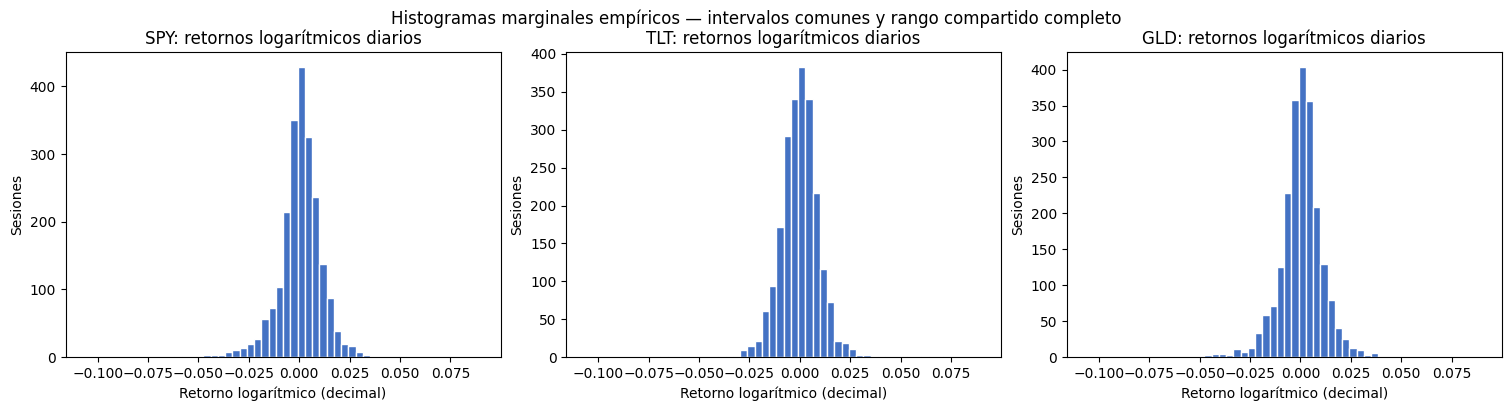

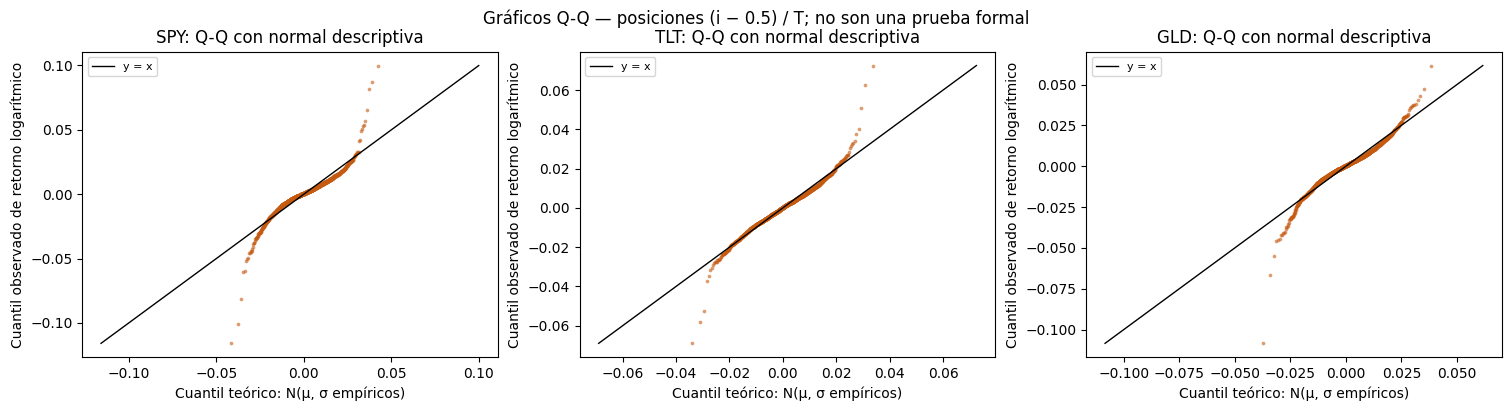

(shape: (3, 13)
 ┌────────┬──────────────┬──────────┬──────────┬───┬──────────┬──────────┬───────────┬──────────────┐
 │ symbol ┆ observations ┆ mean     ┆ std      ┆ … ┆ q95      ┆ q99      ┆ skew      ┆ excess_kurto │
 │ ---    ┆ ---          ┆ ---      ┆ ---      ┆   ┆ ---      ┆ ---      ┆ ---       ┆ sis          │
 │ str    ┆ i64          ┆ f64      ┆ f64      ┆   ┆ f64      ┆ f64      ┆ f64       ┆ ---          │
 │        ┆              ┆          ┆          ┆   ┆          ┆          ┆           ┆ f64          │
 ╞════════╪══════════════╪══════════╪══════════╪═══╪══════════╪══════════╪═══════════╪══════════════╡
 │ SPY    ┆ 2204         ┆ 0.000543 ┆ 0.011978 ┆ … ┆ 0.016015 ┆ 0.026991 ┆ -0.566453 ┆ 13.683094    │
 │ TLT    ┆ 2204         ┆ -0.0001  ┆ 0.009638 ┆ … ┆ 0.014861 ┆ 0.023943 ┆ 0.066811  ┆ 4.97642      │
 │ GLD    ┆ 2204         ┆ 0.000509 ┆ 0.010789 ┆ … ┆ 0.016877 ┆ 0.028704 ┆ -0.738574 ┆ 7.621485     │
 └────────┴──────────────┴──────────┴──────────┴───┴──────────┴───

In [10]:
from statistics import NormalDist
import matplotlib.pyplot as plt

EXPOSURE_EXAMPLES = ('SPY', 'TLT', 'GLD')
missing_examples = [symbol for symbol in EXPOSURE_EXAMPLES if symbol not in return_symbols]
if missing_examples:
    raise RuntimeError(f'Los ejemplos no están en el universo elegible; no se hizo sustitución: {missing_examples}')

example_indices = [return_symbols.index(symbol) for symbol in EXPOSURE_EXAMPLES]
example_order = {symbol: index for index, symbol in enumerate(EXPOSURE_EXAMPLES)}
example_statistics = marginal_statistics.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict(example_order).alias('_example_order')).sort('_example_order').drop('_example_order')

return_dates = np.array(usable_returns['session_date'].to_list())
extreme_rows = []
for symbol, column_index in zip(EXPOSURE_EXAMPLES, example_indices):
    series = log_return_values[:, column_index]
    minimum, maximum = float(series.min()), float(series.max())
    extreme_rows.append({
        'symbol': symbol,
        'minimum': minimum,
        'minimum_dates': ', '.join(str(stamp) for stamp in return_dates[series == minimum]),
        'maximum': maximum,
        'maximum_dates': ', '.join(str(stamp) for stamp in return_dates[series == maximum]),
    })
example_extreme_dates = pl.DataFrame(extreme_rows)

example_values = log_return_values[:, example_indices]
common_lower, common_upper = float(example_values.min()), float(example_values.max())
common_histogram_bins = np.linspace(common_lower, common_upper, 61)
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for axis, symbol, column_index in zip(axes, EXPOSURE_EXAMPLES, example_indices):
    axis.hist(log_return_values[:, column_index], bins=common_histogram_bins, color='#4472C4', edgecolor='white')
    axis.set_title(f'{symbol}: retornos logarítmicos diarios')
    axis.set_xlabel('Retorno logarítmico (decimal)')
    axis.set_ylabel('Sesiones')
    axis.set_xlim(common_lower, common_upper)
fig.suptitle('Histogramas marginales empíricos — intervalos comunes y rango compartido completo', y=1.04)
plt.show()

plotting_positions = (np.arange(1, joint_observation_count + 1) - 0.5) / joint_observation_count
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8), constrained_layout=True)
for axis, symbol, column_index in zip(axes, EXPOSURE_EXAMPLES, example_indices):
    reference = NormalDist(mu=float(marginal_mean[column_index]), sigma=float(marginal_std[column_index]))
    theoretical = np.fromiter((reference.inv_cdf(float(position)) for position in plotting_positions), dtype=float, count=joint_observation_count)
    observed = sorted_log_returns[:, column_index]
    axis.scatter(theoretical, observed, s=7, alpha=0.6, color='#C55A11', linewidths=0)
    line_min, line_max = min(float(theoretical.min()), float(observed.min())), max(float(theoretical.max()), float(observed.max()))
    axis.plot([line_min, line_max], [line_min, line_max], color='black', linewidth=1, label='y = x')
    axis.set_title(f'{symbol}: Q-Q con normal descriptiva')
    axis.set_xlabel('Cuantil teórico: N(μ, σ empíricos)')
    axis.set_ylabel('Cuantil observado de retorno logarítmico')
    axis.legend(loc='best', fontsize=8)
fig.suptitle('Gráficos Q-Q — posiciones (i − 0.5) / T; no son una prueba formal', y=1.04)
plt.show()

example_by_symbol = {row['symbol']: row for row in example_statistics.to_dicts()}
marginal_interpretation = (
    f"En esta muestra, las desviaciones estándar diarias de retornos logarítmicos son SPY={example_by_symbol['SPY']['std']:.6f}, "
    f"TLT={example_by_symbol['TLT']['std']:.6f} y GLD={example_by_symbol['GLD']['std']:.6f}. "
    f"Sus mínimos/máximos empíricos son SPY=({example_by_symbol['SPY']['minimum']:.6f}, {example_by_symbol['SPY']['maximum']:.6f}), "
    f"TLT=({example_by_symbol['TLT']['minimum']:.6f}, {example_by_symbol['TLT']['maximum']:.6f}) y "
    f"GLD=({example_by_symbol['GLD']['minimum']:.6f}, {example_by_symbol['GLD']['maximum']:.6f}). "
    f"El exceso de curtosis es SPY={example_by_symbol['SPY']['excess_kurtosis']:.3f}, "
    f"TLT={example_by_symbol['TLT']['excess_kurtosis']:.3f} y GLD={example_by_symbol['GLD']['excess_kurtosis']:.3f}. "
    'Son diferencias descriptivas de esta ventana: no identifican causas ni demuestran una ley de colas pesadas.'
)

example_statistics, example_extreme_dates, marginal_interpretation


La curtosis y los extremos pueden ser sensibles a pocas observaciones. Las diferencias visuales de los Q-Q no son una prueba formal, y ningún resultado de esta sección justifica un ranking de inversión ni una conclusión sobre la evolución temporal o la dependencia conjunta.

# 3.2. Diagnóstico del comportamiento temporal

La distribución empírica de toda la ventana resume 2,204 sesiones. Aquí se distingue de distribuciones empíricas por subperiodo y de estadísticas móviles: ambas describen cómo cambian características de la muestra a lo largo del tiempo. Este bloque es descriptivo; no es una prueba formal de estacionariedad ni selecciona un modelo predictivo.

Los cortes se fijan antes del cálculo por años calendario, de 2018 a 2026. Cada retorno pertenece al año de su fecha. El año 2026 termina el 2026-10-09 y se identifica explícitamente como parcial; los años no se interpretan aquí como regímenes económicos.

In [11]:
TEMPORAL_ABSOLUTE_TOLERANCE, TEMPORAL_RELATIVE_TOLERANCE = 1e-14, 1e-11
ANNUAL_QUANTILE_CDF_TOLERANCE = 1e-12
annual_quantile_levels = np.array([0.05, 0.50, 0.95], dtype=float)
annual_quantile_labels = ['q05', 'q50', 'q95']
calendar_years = list(range(2018, 2027))
temporal_dates = np.array(usable_returns['session_date'].to_list())
temporal_years = np.array([stamp.year for stamp in temporal_dates], dtype=int)

def discrete_empirical_quantiles(values, levels):
    ordered = np.sort(values, axis=0)
    indices = np.ceil(levels * values.shape[0]).astype(int) - 1
    return ordered[indices, :], ordered

annual_period_rows, annual_stat_rows, annual_means, annual_m2_values, annual_counts, annual_positions = [], [], [], [], [], []
annual_quantile_checks, annual_quantile_observed_checks = [], []
for year in calendar_years:
    positions = np.flatnonzero(temporal_years == year)
    if positions.size == 0:
        raise AssertionError(f'Fixed calendar year has no observed returns: {year}')
    values = log_return_values[positions, :]
    count = values.shape[0]
    probabilities = np.full(count, 1.0 / count, dtype=float)
    mean = np.sum(probabilities[:, None] * values, axis=0)
    centered = values - mean
    m2 = np.sum(probabilities[:, None] * centered**2, axis=0)
    std = np.sqrt(m2)
    quantiles, ordered_values = discrete_empirical_quantiles(values, annual_quantile_levels)

    annual_period_rows.append({
        'year': year,
        'start_date': temporal_dates[positions[0]],
        'end_date': temporal_dates[positions[-1]],
        'observations': count,
        'is_partial_year': year == 2026,
    })
    annual_counts.append(count)
    annual_positions.append(positions)
    annual_means.append(mean)
    annual_m2_values.append(m2)

    for level_index, alpha in enumerate(annual_quantile_levels):
        q_values = quantiles[level_index, :]
        cdf_at_q = np.sum(values <= q_values[None, :], axis=0) / count
        cdf_before_q = np.sum(values < q_values[None, :], axis=0) / count
        annual_quantile_checks.append(bool(np.all(cdf_at_q >= alpha - ANNUAL_QUANTILE_CDF_TOLERANCE) and np.all(cdf_before_q < alpha + ANNUAL_QUANTILE_CDF_TOLERANCE)))
        annual_quantile_observed_checks.append(bool(np.all(np.any(ordered_values == q_values[None, :], axis=0))))

    for symbol_index, symbol in enumerate(return_symbols):
        annual_stat_rows.append({
            'year': year, 'symbol': symbol, 'observations': count,
            'mean': float(mean[symbol_index]), 'std': float(std[symbol_index]),
            **{label: float(quantiles[level_index, symbol_index]) for level_index, label in enumerate(annual_quantile_labels)},
        })

annual_periods = pl.DataFrame(annual_period_rows).sort('year')
annual_marginal_statistics = pl.DataFrame(annual_stat_rows).sort(['year', 'symbol'])
annual_counts_array = np.array(annual_counts, dtype=float)
annual_means_array = np.vstack(annual_means)
annual_m2_array = np.vstack(annual_m2_values)

def max_error_metrics(actual, reference):
    absolute = np.abs(actual - reference)
    nonzero = np.abs(reference) > 0.0
    relative = np.zeros_like(absolute)
    relative[nonzero] = absolute[nonzero] / np.abs(reference[nonzero])
    return float(absolute.max()), float(relative[nonzero].max()) if nonzero.any() else 0.0

all_annual_positions = np.concatenate(annual_positions)
annual_weighted_mean = np.sum((annual_counts_array / joint_observation_count)[:, None] * annual_means_array, axis=0)
annual_variance_decomposition = np.sum((annual_counts_array / joint_observation_count)[:, None] * (annual_m2_array + (annual_means_array - marginal_mean)**2), axis=0)
mean_max_abs_error, mean_max_rel_error = max_error_metrics(annual_weighted_mean, marginal_mean)
variance_max_abs_error, variance_max_rel_error = max_error_metrics(annual_variance_decomposition, marginal_m2)

def trailing_population_std(values, window):
    cumulative = np.vstack([np.zeros((1, values.shape[1])), np.cumsum(values, axis=0)])
    cumulative_squares = np.vstack([np.zeros((1, values.shape[1])), np.cumsum(values**2, axis=0)])
    window_sum = cumulative[window:] - cumulative[:-window]
    window_sum_squares = cumulative_squares[window:] - cumulative_squares[:-window]
    variance = window_sum_squares / window - (window_sum / window)**2
    if np.any(variance < -TEMPORAL_ABSOLUTE_TOLERANCE):
        raise AssertionError('Numerically invalid negative trailing variance encountered.')
    output = np.full(values.shape, np.nan)
    output[window - 1:, :] = np.sqrt(np.maximum(variance, 0.0))
    return output

rolling_windows = (63, 252)
rolling_volatility = {window: trailing_population_std(log_return_values, window) for window in rolling_windows}
rolling_checks = {}
rolling_error_rows = []
for window, values in rolling_volatility.items():
    leading_missing = int(np.isnan(values[:window - 1, :]).sum())
    first_direct = np.std(log_return_values[:window, :], axis=0, ddof=0)
    last_direct = np.std(log_return_values[-window:, :], axis=0, ddof=0)
    first_abs, first_rel = max_error_metrics(values[window - 1, :], first_direct)
    last_abs, last_rel = max_error_metrics(values[-1, :], last_direct)
    rolling_checks[f'{window} sesiones: valores iniciales no disponibles'] = leading_missing == (window - 1) * joint_instrument_count
    rolling_checks[f'{window} sesiones: ventanas completas finitas y no negativas'] = bool(np.isfinite(values[window - 1:, :]).all() and (values[window - 1:, :] >= 0.0).all())
    rolling_checks[f'{window} sesiones: primera y última ventana vs cálculo directo'] = bool(first_abs <= TEMPORAL_ABSOLUTE_TOLERANCE + TEMPORAL_RELATIVE_TOLERANCE * np.abs(first_direct).max() and last_abs <= TEMPORAL_ABSOLUTE_TOLERANCE + TEMPORAL_RELATIVE_TOLERANCE * np.abs(last_direct).max())
    rolling_error_rows.append({'window_sessions': window, 'first_window_max_absolute_error': first_abs, 'first_window_max_relative_error': first_rel, 'last_window_max_absolute_error': last_abs, 'last_window_max_relative_error': last_rel})

temporal_checks = {
    'Subperiodos anuales cubren cada fecha una vez y en orden': bool(np.array_equal(all_annual_positions, np.arange(joint_observation_count))),
    'Conteos anuales suman 2,204': int(annual_counts_array.sum()) == joint_observation_count,
    'Medias anuales ponderadas concilian con la ventana completa': bool(mean_max_abs_error <= TEMPORAL_ABSOLUTE_TOLERANCE + TEMPORAL_RELATIVE_TOLERANCE * np.abs(marginal_mean).max()),
    'Descomposición anual de varianza concilia con la ventana completa': bool(variance_max_abs_error <= TEMPORAL_ABSOLUTE_TOLERANCE + TEMPORAL_RELATIVE_TOLERANCE * np.abs(marginal_m2).max()),
    'Cuantiles anuales ordenados y valores observados': all(annual_quantile_observed_checks),
    'Definición CDF empírica válida para cada cuantil anual': all(annual_quantile_checks),
    **rolling_checks,
}
if not all(temporal_checks.values()):
    failed_checks = [name for name, passed in temporal_checks.items() if not passed]
    raise AssertionError(f'La validación temporal falló sin alterar los datos: {failed_checks}')

reconciliation_error_summary = pl.DataFrame({
    'identity': ['Medias: global vs anual ponderada', 'Varianzas: global vs descomposición anual'],
    'max_absolute_error': [mean_max_abs_error, variance_max_abs_error],
    'max_relative_error_nonzero_reference': [mean_max_rel_error, variance_max_rel_error],
})
temporal_error_summary = pl.DataFrame(rolling_error_rows)
temporal_check_summary = pl.DataFrame({'check': list(temporal_checks), 'result': ['PASS' if passed else 'FAIL' for passed in temporal_checks.values()]})
example_annual_statistics = annual_marginal_statistics.filter(pl.col('symbol').is_in(EXPOSURE_EXAMPLES)).with_columns(pl.col('symbol').replace_strict({symbol: index for index, symbol in enumerate(EXPOSURE_EXAMPLES)}).alias('_example_order')).sort(['year', '_example_order']).drop('_example_order')
from IPython.display import display
with pl.Config(tbl_rows=30):
    display(annual_periods)
    display(example_annual_statistics)
reconciliation_error_summary, temporal_error_summary, temporal_check_summary


year,start_date,end_date,observations,is_partial_year
i64,date,date,i64,bool
2018,2018-01-03,2018-12-31,250,false
2019,2019-01-02,2019-12-31,252,false
2020,2020-01-02,2020-12-31,253,false
2021,2021-01-04,2021-12-31,252,false
2022,2022-01-03,2022-12-30,251,false
2023,2023-01-03,2023-12-29,250,false
2024,2024-01-02,2024-12-31,252,false
2025,2025-01-02,2025-12-31,250,false
2026,2026-01-02,2026-10-09,194,true


year,symbol,observations,mean,std,q05,q50,q95
i64,str,i64,f64,f64,f64,f64,f64
2018,"""SPY""",250,-0.000215,0.010749,-0.021545,0.000293,0.01471
2018,"""TLT""",250,-0.000021,0.005799,-0.009333,-0.000082,0.008771
2018,"""GLD""",250,-0.000127,0.00609,-0.010552,0.0,0.010727
2019,"""SPY""",252,0.001078,0.007877,-0.012248,0.00104,0.012692
2019,"""TLT""",252,0.000524,0.007501,-0.013352,0.001216,0.012441
2019,"""GLD""",252,0.000652,0.007324,-0.011614,0.00083,0.013885
2020,"""SPY""",253,0.000667,0.021152,-0.033728,0.002257,0.026657
2020,"""TLT""",253,0.000659,0.013526,-0.016267,0.000598,0.016875
2020,"""GLD""",253,0.000876,0.012277,-0.01989,0.002158,0.01948


(shape: (2, 3)
 ┌─────────────────────────────────┬────────────────────┬─────────────────────────────────┐
 │ identity                        ┆ max_absolute_error ┆ max_relative_error_nonzero_ref… │
 │ ---                             ┆ ---                ┆ ---                             │
 │ str                             ┆ f64                ┆ f64                             │
 ╞═════════════════════════════════╪════════════════════╪═════════════════════════════════╡
 │ Medias: global vs anual ponder… ┆ 1.3010e-18         ┆ 1.8017e-14                      │
 │ Varianzas: global vs descompos… ┆ 1.7347e-18         ┆ 8.5608e-16                      │
 └─────────────────────────────────┴────────────────────┴─────────────────────────────────┘,
 shape: (2, 5)
 ┌─────────────────┬────────────────────┬───────────────────┬───────────────────┬───────────────────┐
 │ window_sessions ┆ first_window_max_a ┆ first_window_max_ ┆ last_window_max_a ┆ last_window_max_r │
 │ ---             ┆ bsolute_

## Volatilidad móvil y comparación anual

La volatilidad móvil es la desviación estándar diaria de log-retornos en una ventana retrospectiva que incluye la sesión mostrada. Se exigen ventanas completas, con `ddof=0` y pesos uniformes; no se rellenan los valores iniciales no disponibles. Las ventanas se solapan, por lo que estimaciones consecutivas no son independientes. Describen dispersión reciente, no un pronóstico automático.

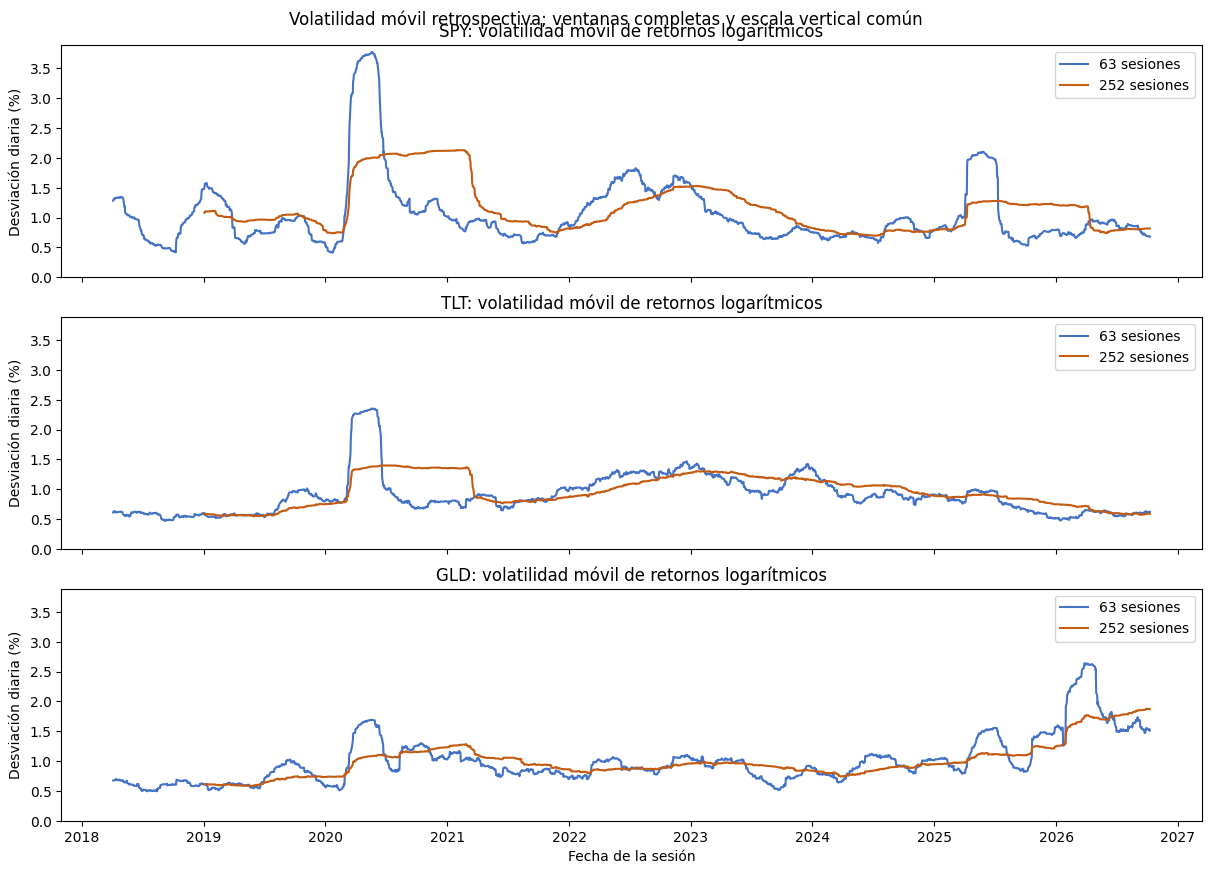

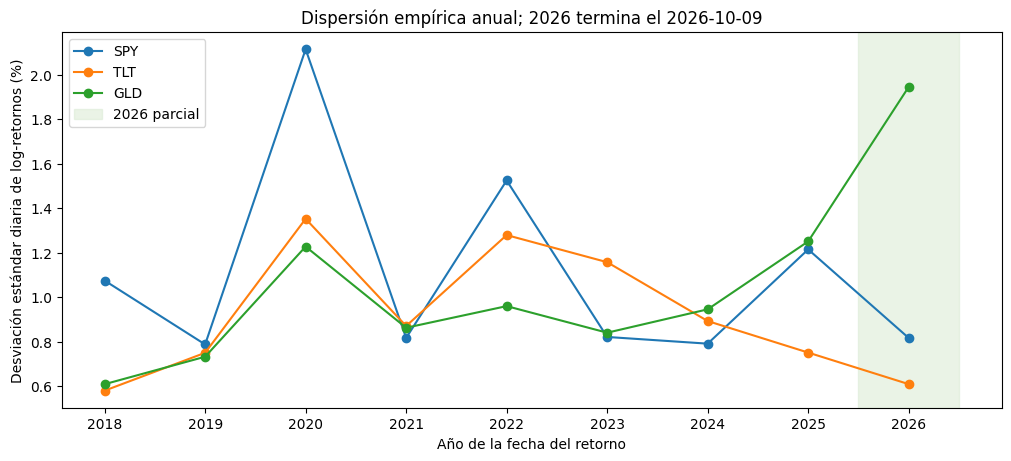

'En esta muestra, la desviación anual diaria mínima/máxima de SPY fue 0.007877 (2019) / 0.021152 (2020); para TLT fue 0.005799 (2018) / 0.013526 (2020); y para GLD fue 0.006090 (2018) / 0.019458 (2026). Al cierre, las volatilidades móviles de 63/252 sesiones son SPY=0.006803/0.008180, TLT=0.006236/0.005903 y GLD=0.015100/0.018735. La distribución de toda la ventana puede mezclar periodos con dispersión distinta; parte de las diferencias también puede reflejar variabilidad muestral. Estas gráficas no establecen estacionariedad, no estacionariedad ni causas, y no recomiendan todavía ventanas, ponderaciones o modelos.'

In [12]:
example_indices = [return_symbols.index(symbol) for symbol in EXPOSURE_EXAMPLES]
common_volatility_upper = max(float(rolling_volatility[window][window - 1:, example_indices].max()) for window in rolling_windows) * 100.0
fig, axes = plt.subplots(3, 1, figsize=(12, 8.5), sharex=True, sharey=True, constrained_layout=True)
for axis, symbol, column_index in zip(axes, EXPOSURE_EXAMPLES, example_indices):
    axis.plot(temporal_dates, rolling_volatility[63][:, column_index] * 100.0, label='63 sesiones', color='#4472C4')
    axis.plot(temporal_dates, rolling_volatility[252][:, column_index] * 100.0, label='252 sesiones', color='#C55A11')
    axis.set_title(f'{symbol}: volatilidad móvil de retornos logarítmicos')
    axis.set_ylabel('Desviación diaria (%)')
    axis.set_ylim(0.0, common_volatility_upper * 1.03)
    axis.legend(loc='upper right')
axes[-1].set_xlabel('Fecha de la sesión')
fig.suptitle('Volatilidad móvil retrospectiva; ventanas completas y escala vertical común', y=1.01)
plt.show()

fig, axis = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
for symbol in EXPOSURE_EXAMPLES:
    annual_view = example_annual_statistics.filter(pl.col('symbol') == symbol).sort('year')
    axis.plot(annual_view['year'].to_list(), (annual_view['std'] * 100.0).to_list(), marker='o', label=symbol)
axis.axvspan(2025.5, 2026.5, color='#D9EAD3', alpha=0.55, label='2026 parcial')
axis.set_xticks(calendar_years)
axis.set_xlabel('Año de la fecha del retorno')
axis.set_ylabel('Desviación estándar diaria de log-retornos (%)')
axis.set_title('Dispersión empírica anual; 2026 termina el 2026-10-09')
axis.legend(loc='best')
plt.show()

def annual_std_range(symbol):
    values = example_annual_statistics.filter(pl.col('symbol') == symbol).sort('year')
    minimum_row = values.sort('std').row(0, named=True)
    maximum_row = values.sort('std', descending=True).row(0, named=True)
    return minimum_row, maximum_row

annual_ranges = {symbol: annual_std_range(symbol) for symbol in EXPOSURE_EXAMPLES}
latest_rolling = {symbol: {window: float(rolling_volatility[window][-1, return_symbols.index(symbol)]) for window in rolling_windows} for symbol in EXPOSURE_EXAMPLES}
temporal_interpretation = (
    f"En esta muestra, la desviación anual diaria mínima/máxima de SPY fue {annual_ranges['SPY'][0]['std']:.6f} ({annual_ranges['SPY'][0]['year']}) / {annual_ranges['SPY'][1]['std']:.6f} ({annual_ranges['SPY'][1]['year']}); "
    f"para TLT fue {annual_ranges['TLT'][0]['std']:.6f} ({annual_ranges['TLT'][0]['year']}) / {annual_ranges['TLT'][1]['std']:.6f} ({annual_ranges['TLT'][1]['year']}); "
    f"y para GLD fue {annual_ranges['GLD'][0]['std']:.6f} ({annual_ranges['GLD'][0]['year']}) / {annual_ranges['GLD'][1]['std']:.6f} ({annual_ranges['GLD'][1]['year']}). "
    f"Al cierre, las volatilidades móviles de 63/252 sesiones son SPY={latest_rolling['SPY'][63]:.6f}/{latest_rolling['SPY'][252]:.6f}, "
    f"TLT={latest_rolling['TLT'][63]:.6f}/{latest_rolling['TLT'][252]:.6f} y GLD={latest_rolling['GLD'][63]:.6f}/{latest_rolling['GLD'][252]:.6f}. "
    'La distribución de toda la ventana puede mezclar periodos con dispersión distinta; parte de las diferencias también puede reflejar variabilidad muestral. Estas gráficas no establecen estacionariedad, no estacionariedad ni causas, y no recomiendan todavía ventanas, ponderaciones o modelos.'
)
temporal_interpretation


Los años, las estadísticas móviles y sus diferencias visuales son cortes descriptivos predefinidos. Este diagnóstico no incorpora correlaciones, dependencia conjunta, pruebas formales de estacionariedad, remuestreo, decaimiento temporal ni escenarios futuros.

## Siguiente paso: transformaciones de retornos

Pendiente de desarrollar con el usuario. Esta notebook se detiene después de la carga y validación de entradas.